<h1 style="text-align:center; font-family:'Times New Roman';">
Skin Cancer Classification and Explainability Using Deep Learning (1)
</h1>

This notebook presents the development and evaluation of two deep learning architectures, ConvNeXt-Tiny and Swin-Tiny, for binary skin cancer classification (Benign vs. Malignant).

It covers the dataset preparation, image preprocessing, model training, and performance evaluation. Both architectures are compared using several classification metrics to identify their strengths and limitations.

**Chargement et exploration de dataset**

In [ ]:
import hashlib
import shutil
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

# Chemins
BASE_DIR = Path(
    "/kaggle/input/datasets/hasnainjaved/"
    "melanoma-skin-cancer-dataset-of-10000-images/"
    "melanoma_cancer_dataset"
)

DEST_DIR = Path("/kaggle/working/skin_cancer_clean")

CLASSES = ["benign", "malignant"]

Nombre total d'images : 10605


label,benign,malignant,All
split,,,
test,500,500,1000
train,5000,4605,9605
All,5500,5105,10605


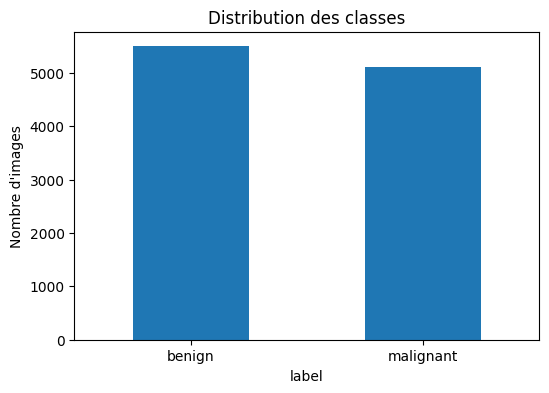

In [4]:
records = []

for split in ["train", "test"]:
    for label in CLASSES:

        folder = BASE_DIR / split / label

        for path in sorted(folder.glob("*.jpg")):
            records.append({
                "path": path,
                "split": split,
                "label": label
            })

df = pd.DataFrame(records)

print("Nombre total d'images :", len(df))

distribution = pd.crosstab(
    df["split"], df["label"], margins=True
)

display(distribution)

# Distribution des classes
df["label"].value_counts().plot(
    kind="bar", figsize=(6, 4), rot=0
)

plt.title("Distribution des classes")
plt.ylabel("Nombre d'images")
plt.show()

In [5]:
def calculate_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


hashes = []
image_errors = []

for path in df["path"]:

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            img.load()
            hashes.append(calculate_hash(path))

    except Exception as e:
        hashes.append(None)
        image_errors.append((path, str(e)))

df["hash"] = hashes

print("Images lisibles :", df["hash"].notna().sum())
print("Images corrompues :", len(image_errors))

if image_errors:
    display(pd.DataFrame(image_errors, columns=["path", "error"]))
    raise ValueError("Des images doivent être vérifiées.")

# Groupes de doublons
duplicate_groups = df.groupby("hash").filter(
    lambda group: len(group) > 1
)

print(
    "Groupes de doublons exacts :",
    duplicate_groups["hash"].nunique()
)

# Doublons entre Train et Test
cross_duplicates = df.groupby("hash").filter(
    lambda group: group["split"].nunique() > 1
)

print(
    "Groupes de doublons Train/Test :",
    cross_duplicates["hash"].nunique()
)

# Vérification des labels
conflicts = df.groupby("hash")["label"].nunique()

if (conflicts > 1).any():
    raise ValueError("Certaines images identiques ont des labels différents.")

Images lisibles : 10605
Images corrompues : 0
Groupes de doublons exacts : 22
Groupes de doublons Train/Test : 7


In [6]:
# Garder une seule image par hash, avec priorité au Test
clean_df = (
    df.sort_values("split", key=lambda col: col.map({"test": 0, "train": 1}))
      .drop_duplicates(subset="hash")
      .copy()
)

print("Images initiales :", len(df))
print("Images après nettoyage :", len(clean_df))
print("Images supprimées :", len(df) - len(clean_df))

# Séparation Train / Validation
train_df = clean_df[clean_df["split"] == "train"]
test_df = clean_df[clean_df["split"] == "test"]

train_part, valid_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["label"]
)

# Recréer le dossier de sortie proprement
if DEST_DIR.exists():
    shutil.rmtree(DEST_DIR)

# Fonction de copie
def copy_images(data, split):

    for row in data.itertuples():
        destination = DEST_DIR / split / row.label
        destination.mkdir(parents=True, exist_ok=True)

        shutil.copy2(row.path, destination / row.path.name)


copy_images(train_part, "train")
copy_images(valid_part, "valid")
copy_images(test_df, "test")

print("Dataset nettoyé et organisé :", DEST_DIR)

Images initiales : 10605
Images après nettoyage : 10583
Images supprimées : 22
Dataset nettoyé et organisé : /kaggle/working/skin_cancer_clean


In [7]:
final_records = []

for split in ["train", "valid", "test"]:
    for label in CLASSES:

        folder = DEST_DIR / split / label

        for path in folder.glob("*.jpg"):
            final_records.append({
                "split": split,
                "label": label,
                "hash": calculate_hash(path)
            })

final_df = pd.DataFrame(final_records)

display(pd.crosstab(
    final_df["split"],
    final_df["label"],
    margins=True
))

print("Total final :", len(final_df))

# Vérification des doublons
remaining = final_df.groupby("hash")["split"].nunique()

print(
    "Groupes de doublons entre ensembles :",
    (remaining > 1).sum()
)

label,benign,malignant,All
split,,,
test,499,500,999
train,3992,3675,7667
valid,998,919,1917
All,5489,5094,10583


Total final : 10583
Groupes de doublons entre ensembles : 0


In [8]:
import shutil

shutil.make_archive("/kaggle/working/skin_cancer_clean","zip", "/kaggle/working/skin_cancer_clean")

'/kaggle/working/skin_cancer_clean.zip'

## Prétraitement des images

In [9]:
# Imports nécessaires au prétraitement et au chargement des images
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path

# Chemins du dataset nettoyé
DATA_DIR = Path("/kaggle/working/skin_cancer_clean")

TRAIN_DIR = DATA_DIR / "train"
VALID_DIR = DATA_DIR / "valid"
TEST_DIR = DATA_DIR / "test"

# Vérification des dossiers
assert all(p.exists() for p in [TRAIN_DIR, VALID_DIR, TEST_DIR]), \
    "Un ou plusieurs dossiers du dataset sont introuvables."

# Configuration générale
IMG_SIZE = 224
BATCH_SIZE = 32

# Utilisation du GPU s'il est disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)
print("Taille des images :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)

Device : cuda
Taille des images : 224
Batch size : 32


In [6]:
# Valeurs de normalisation ImageNet utilisées avec les modèles pré-entraînés
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Transformations appliquées uniquement aux images d'entraînement
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Transformations sans augmentation pour validation et test
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

In [7]:
# Chargement des trois ensembles avec leurs transformations respectives
train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    root=VALID_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)

# Vérifier que les classes sont identiques dans les trois ensembles
print("Classes :", train_dataset.classes)
print("Correspondance des labels :", train_dataset.class_to_idx)

assert train_dataset.class_to_idx == valid_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

# Afficher le nombre d'images par ensemble
print("\nNombre d'images :")
print("Train :", len(train_dataset))
print("Validation :", len(valid_dataset))
print("Test :", len(test_dataset))

Classes : ['benign', 'malignant']
Correspondance des labels : {'benign': 0, 'malignant': 1}

Nombre d'images :
Train : 7667
Validation : 1917
Test : 999


In [5]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(
    train_dir,
    transform=train_transform
)

valid_dataset = ImageFolder(
    valid_dir,
    transform=eval_transform
)

test_dataset = ImageFolder(
    test_dir,
    transform=eval_transform
)

print("Train :", len(train_dataset))
print("Validation :", len(valid_dataset))
print("Test :", len(test_dataset))

Train : 7667
Validation : 1917
Test : 999


In [8]:
# Préparation des lots d'images pour chaque ensemble
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Nombre de batches :")
print("Train :", len(train_loader))
print("Validation :", len(valid_loader))
print("Test :", len(test_loader))

Nombre de batches :
Train : 240
Validation : 60
Test : 32


In [11]:
# Récupérer un batch d'images et leurs labels
images, labels = next(iter(train_loader))

print("Dimensions des images :", images.shape)
print("Dimensions des labels :", labels.shape)
print("Type des images :", images.dtype)
print("Type des labels :", labels.dtype)
print("Labels présents :", labels.unique().tolist())

# Vérifier la forme attendue par les modèles
assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)
assert labels.ndim == 1

print("\nVérification réussie : les images sont prêtes.")

Dimensions des images : torch.Size([32, 3, 224, 224])
Dimensions des labels : torch.Size([32])
Type des images : torch.float32
Type des labels : torch.int64
Labels présents : [0, 1]

Vérification réussie : les images sont prêtes.


## Entraînement de ConvNeXt-Tiny

Chargement du modèle pré-entraîné

In [15]:
import torch.nn as nn
from torchvision import models

# Je charge ConvNeXt-Tiny avec les poids pré-entraînés sur ImageNet.
# Je réutilise ainsi les connaissances déjà acquises par le modèle
# pour extraire des caractéristiques visuelles comme les contours, les textures et les formes.
weights = models.ConvNeXt_Tiny_Weights.DEFAULT
model = models.convnext_tiny(weights=weights)

# Je récupère le nombre d'entrées de la dernière couche
# pour pouvoir la remplacer tout en conservant la structure du modèle.
in_features = model.classifier[2].in_features

# Je remplace la dernière couche de classification pour adapter le modèle
# à mes deux classes : benign et malignant.
model.classifier[2] = nn.Linear(in_features, 2)

# Je place le modèle sur le GPU s'il est disponible, sinon sur le CPU.
model = model.to(device)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 225MB/s] 


Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=2, bias=True)
)


Définition de la fonction de perte et de l'optimiseur

In [16]:
# Je choisis CrossEntropyLoss pour mesurer l'écart entre les prédictions
# du modèle et les vraies classes (benign et malignant).
criterion = nn.CrossEntropyLoss()

# Je choisis AdamW pour ajuster les poids du modèle pendant l'apprentissage.
# Le learning rate contrôle l'ampleur des mises à jour,
# tandis que weight_decay permet de limiter le surapprentissage.

optimizer = torch.optim.AdamW(model.parameters(),lr=1e-4,weight_decay=1e-4)

# Je définis le nombre de passages complets sur les données d'entraînement.
EPOCHS = 10

print("Fonction de perte :", criterion)
print("Optimiseur :", optimizer)
print("Nombre d'époques :", EPOCHS)

Fonction de perte : CrossEntropyLoss()
Optimiseur : AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Nombre d'époques : 10


Fonction d'entraînement

In [14]:
def train_one_epoch(model, loader, criterion, optimizer):
    # Je place le modèle en mode entraînement pour autoriser la mise à jour des poids.
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        # Je transfère les images et leurs labels vers le même appareil que le modèle.
        images = images.to(device)
        labels = labels.to(device)

        # Je réinitialise les gradients avant de calculer les nouvelles mises à jour.
        optimizer.zero_grad()

        # Je demande au modèle de prédire les classes et je calcule son erreur.
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Je rétropropage l'erreur puis je mets à jour les poids du modèle.
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Je récupère la classe ayant obtenu le score le plus élevé
        # et je compte les prédictions correctes.
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    # Je calcule la perte moyenne et l'accuracy sur toute l'époque.
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

Fonction de validation

In [15]:
def evaluate(model, loader, criterion):
    # Je place le modèle en mode évaluation pour mesurer ses performances.
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    # Je désactive le calcul des gradients puisque je ne modifie pas les poids.
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            # Je calcule les prédictions et la perte sur les données de validation.
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            # Je compare les classes prédites aux vraies classes.
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    # Je calcule les performances moyennes sur l'ensemble de validation.
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

Lancement de l'entrainemnt 

In [20]:
# Je prépare un historique pour conserver les performances
# de Train et Validation à chaque époque.
history = {
    "train_loss": [],
    "train_accuracy": [],
    "valid_loss": [],
    "valid_accuracy": []
}

# J'initialise la meilleure perte de validation à l'infini
# afin de sauvegarder le modèle dès la première époque.
best_valid_loss = float("inf")
MODEL_PATH = "/kaggle/working/best_convnext_tiny.pth"

for epoch in range(EPOCHS):

    # J'entraîne le modèle sur les données Train et je récupère ses performances.
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer
    )

    # J'évalue le modèle sur Validation sans modifier ses poids.
    valid_loss, valid_acc = evaluate(
        model, valid_loader, criterion
    )

    # Je conserve les résultats de chaque époque pour tracer les courbes.
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["valid_loss"].append(valid_loss)
    history["valid_accuracy"].append(valid_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print(f"Train      | Loss: {train_loss:.4f} | Accuracy: {train_acc:.4f}")
    print(f"Validation | Loss: {valid_loss:.4f} | Accuracy: {valid_acc:.4f}")
    print("-" * 55)

    # Je sauvegarde le modèle uniquement lorsque sa perte de validation diminue.
    # le meilleur modèle choisit selon valid_loss, pas selon valid_accuracy
    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "valid_loss": valid_loss,
            "valid_accuracy": valid_acc
        }, MODEL_PATH)

        print("Meilleur modèle sauvegardé.")

print("Entraînement terminé.")
print("Chemin du meilleur modèle :", MODEL_PATH)

Epoch [1/10]
Train      | Loss: 0.2241 | Accuracy: 0.9069
Validation | Loss: 0.1563 | Accuracy: 0.9395
-------------------------------------------------------
Meilleur modèle sauvegardé.
Epoch [2/10]
Train      | Loss: 0.1524 | Accuracy: 0.9395
Validation | Loss: 0.1336 | Accuracy: 0.9421
-------------------------------------------------------
Meilleur modèle sauvegardé.
Epoch [3/10]
Train      | Loss: 0.1231 | Accuracy: 0.9508
Validation | Loss: 0.1358 | Accuracy: 0.9431
-------------------------------------------------------
Epoch [4/10]
Train      | Loss: 0.0995 | Accuracy: 0.9594
Validation | Loss: 0.1746 | Accuracy: 0.9400
-------------------------------------------------------
Epoch [5/10]
Train      | Loss: 0.0975 | Accuracy: 0.9644
Validation | Loss: 0.1489 | Accuracy: 0.9463
-------------------------------------------------------
Epoch [6/10]
Train      | Loss: 0.0692 | Accuracy: 0.9726
Validation | Loss: 0.1402 | Accuracy: 0.9484
----------------------------------------------

In [23]:
import os
import shutil
import zipfile
from IPython.display import FileLink, display

MODELS_DIR = "/kaggle/working/models"
os.makedirs(MODELS_DIR, exist_ok=True)

shutil.copy(
    MODEL_PATH,
    os.path.join(MODELS_DIR, "best_convnext_tiny.pth")
)

ZIP_PATH = "/kaggle/working/models.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(MODELS_DIR):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, "/kaggle/working")
            zipf.write(file_path, arcname)

print("Dossier des modèles créé :", MODELS_DIR)
print("Archive créée :", ZIP_PATH)
print("Modèle enregistré : best_convnext_tiny.pth")


display(FileLink("/kaggle/working/models.zip"))

Dossier des modèles créé : /kaggle/working/models
Archive créée : /kaggle/working/models.zip
Modèle enregistré : best_convnext_tiny.pth


/kaggle/working/models.zip

## Courbe d'apprentissage 

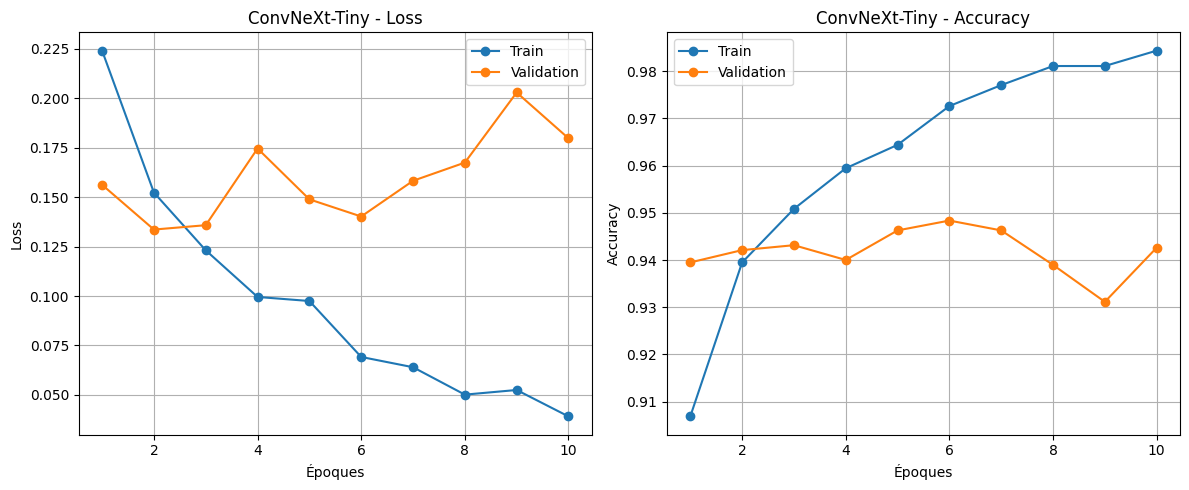

In [21]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Je trace l'évolution de la perte pour observer la diminution des erreurs.
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], marker="o", label="Train")
plt.plot(epochs_range, history["valid_loss"], marker="o", label="Validation")
plt.title("ConvNeXt-Tiny - Loss")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Je trace l'évolution de l'accuracy pour suivre la progression des prédictions.
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_accuracy"], marker="o", label="Train")
plt.plot(epochs_range, history["valid_accuracy"], marker="o", label="Validation")
plt.title("ConvNeXt-Tiny - Accuracy")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Courbe Train :
- La Loss diminue régulièrement de 0,224 à environ 0,04.
- L'Accuracy augmente de 90,7 % à environ 98,4 %.
  
--> Cela montre que ConvNeXt-Tiny apprend progressivement     à reconnaître les images d'entraînement.

Courbe Validation :
- La Loss atteint son minimum à l'époque 2 : 0,1336.
- Ensuite, elle remonte globalement, malgré quelques        fluctuations.
- L'Accuracy reste autour de 94 %, avec un maximum proche    de 94,8 % à l'époque 6.
  
-->Cela indique un phénomène de surapprentissage (overfitting).



Charger le meilleure modèle

In [24]:
# je récupère les poids enregistrés de la dernière époque (ep 10 )dans le fichier .
checkpoint = torch.load(MODEL_PATH, map_location=device)

# Je restaure les poids correspondant à la meilleure époque.
model.load_state_dict(checkpoint["model_state_dict"])

# Je place le modèle en mode évaluation pour les prochaines étapes.
model.eval()

print("Meilleur modèle chargé.")
print("Époque retenue :", checkpoint["epoch"])
print(f"Validation Loss : {checkpoint['valid_loss']:.4f}")
print(f"Validation Accuracy : {checkpoint['valid_accuracy']:.4f}")

Meilleur modèle chargé.
Époque retenue : 2
Validation Loss : 0.1336
Validation Accuracy : 0.9421


## Entrainement du modèle Swin-Tiny

Recréer l'environnement :

Après l'interruption de la session Kaggle, les variables et les objets chargés en mémoire ont été perdus. Je recrée donc l'environnement nécessaire pour poursuivre avec Swin-Tiny, en réutilisant le dataset nettoyé et le modèle ConvNeXt sauvegardés. Je réexécute également certaines cellules de la partie Prétraitement des images pour restaurer les transformations et les DataLoaders, sans refaire le nettoyage des données.

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Je vérifie si un GPU est disponible pour accélérer l'entraînement.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Je récupère les chemins du dataset déjà nettoyé.
BASE_DIR = "/kaggle/input/datasets/aminaelmoubtahij/skin-cancer-clean"
# Je récupère les chemins du meilleur modèle de convexnet.
CONVNEXT_PATH = "/kaggle/input/models/aminaelmoubtahij/best-convnext-tiny/pytorch/default/1/best_convnext_tiny.pth"
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VALID_DIR = os.path.join(BASE_DIR, "valid")
TEST_DIR = os.path.join(BASE_DIR, "test")

IMG_SIZE = 224
BATCH_SIZE = 32

print("Device :", device)
print("Dataset disponible :", os.path.exists(TRAIN_DIR))
print("Modèle ConvNeXt disponible :", os.path.exists(CONVNEXT_PATH))

Device : cuda
Dataset disponible : True
Modèle ConvNeXt disponible : True


In [12]:
import torch
import torch.nn as nn
from torchvision import models

# Je charge Swin-Tiny avec ses poids pré-entraînés sur ImageNet.
weights = models.Swin_T_Weights.DEFAULT
model_swin = models.swin_t(weights=weights)

# Je remplace la dernière couche pour obtenir deux classes :
# bénigne (0) et maligne (1).
in_features = model_swin.head.in_features
model_swin.head = nn.Linear(in_features, 2)

# Je place le modèle sur le périphérique disponible.
model_swin = model_swin.to(device)

print(model_swin)

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 245MB/s] 


SwinTransformer(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): Permute()
      (2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
    )
    (1): Sequential(
      (0): SwinTransformerBlock(
        (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
        (attn): ShiftedWindowAttention(
          (qkv): Linear(in_features=96, out_features=288, bias=True)
          (proj): Linear(in_features=96, out_features=96, bias=True)
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
        (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
        (mlp): MLP(
          (0): Linear(in_features=96, out_features=384, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=384, out_features=96, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (1): SwinTransformerBlock(
       

--> Swin-Tiny commence par découper l'image en petits patches à l'aide de Conv2d, analyse les relations entre ces patches grâce à ShiftedWindowAttention, réduit progressivement la résolution tout en enrichissant les caractéristiques avec PatchMerging, puis utilise une couche Linear (768 → 2) pour prédire la classe : bénigne ou maligne.

In [13]:
# Je configure la fonction de perte et l'optimiseur pour Swin-Tiny,
# en conservant les mêmes paramètres que ConvNeXt pour comparer les modèles.

criterion_swin = nn.CrossEntropyLoss()

optimizer_swin = torch.optim.AdamW(
    model_swin.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

EPOCHS = 10

print("Fonction de perte :", criterion_swin)
print("Optimiseur :", optimizer_swin)
print("Nombre d'époques :", EPOCHS)

Fonction de perte : CrossEntropyLoss()
Optimiseur : AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Nombre d'époques : 10


je réexécute les fonctions train_one_epoch et evaluate, déjà définies dans la partie ConvNeXt-Tiny. 

In [16]:
# Je prépare un historique pour conserver les performances
# de Swin-Tiny pendant l'entraînement et la validation.
history_swin = {
    "train_loss": [],
    "train_accuracy": [],
    "valid_loss": [],
    "valid_accuracy": []
}

# Je sauvegarde le modèle qui obtient la meilleure perte de validation.
best_valid_loss_swin = float("inf")
MODEL_PATH_SWIN = "/kaggle/working/best_swin_tiny.pth"

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model_swin, train_loader, criterion_swin, optimizer_swin
    )

    valid_loss, valid_acc = evaluate(
        model_swin, valid_loader, criterion_swin
    )

    history_swin["train_loss"].append(train_loss)
    history_swin["train_accuracy"].append(train_acc)
    history_swin["valid_loss"].append(valid_loss)
    history_swin["valid_accuracy"].append(valid_acc)

    # Je conserve uniquement le modèle ayant la meilleure perte de validation.
    if valid_loss < best_valid_loss_swin:
        best_valid_loss_swin = valid_loss
        torch.save(model_swin.state_dict(), MODEL_PATH_SWIN)

    print(
        f"Époque [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Valid Loss: {valid_loss:.4f} | "
        f"Valid Acc: {valid_acc:.4f}"
    )

Époque [1/10] Train Loss: 0.2405 | Train Acc: 0.9047 | Valid Loss: 0.1742 | Valid Acc: 0.9384
Époque [2/10] Train Loss: 0.1792 | Train Acc: 0.9309 | Valid Loss: 0.1554 | Valid Acc: 0.9447
Époque [3/10] Train Loss: 0.1636 | Train Acc: 0.9380 | Valid Loss: 0.1529 | Valid Acc: 0.9390
Époque [4/10] Train Loss: 0.1489 | Train Acc: 0.9425 | Valid Loss: 0.1416 | Valid Acc: 0.9447
Époque [5/10] Train Loss: 0.1473 | Train Acc: 0.9448 | Valid Loss: 0.1402 | Valid Acc: 0.9411
Époque [6/10] Train Loss: 0.1237 | Train Acc: 0.9500 | Valid Loss: 0.1390 | Valid Acc: 0.9484
Époque [7/10] Train Loss: 0.1209 | Train Acc: 0.9533 | Valid Loss: 0.1294 | Valid Acc: 0.9504
Époque [8/10] Train Loss: 0.1087 | Train Acc: 0.9555 | Valid Loss: 0.1372 | Valid Acc: 0.9494
Époque [9/10] Train Loss: 0.1123 | Train Acc: 0.9601 | Valid Loss: 0.1346 | Valid Acc: 0.9463
Époque [10/10] Train Loss: 0.1031 | Train Acc: 0.9593 | Valid Loss: 0.1645 | Valid Acc: 0.9322


In [77]:
# Je recharge les poids correspondant à la meilleure perte de validation.
checkpoint = torch.load(MODEL_PATH_SWIN, map_location=device)
model_swin.load_state_dict(checkpoint)

# Je place le modèle en mode évaluation.
model_swin.eval()

best_epoch_swin = history_swin["valid_loss"].index(best_valid_loss_swin) + 1

print("Meilleur modèle Swin-Tiny chargé.")
print("Époque retenue :", best_epoch_swin)
print("Validation Loss :", round(best_valid_loss_swin, 4))
print("Validation Accuracy :", round(history_swin["valid_accuracy"][best_epoch_swin - 1], 4))

Meilleur modèle Swin-Tiny chargé.
Époque retenue : 7
Validation Loss : 0.1294
Validation Accuracy : 0.9504


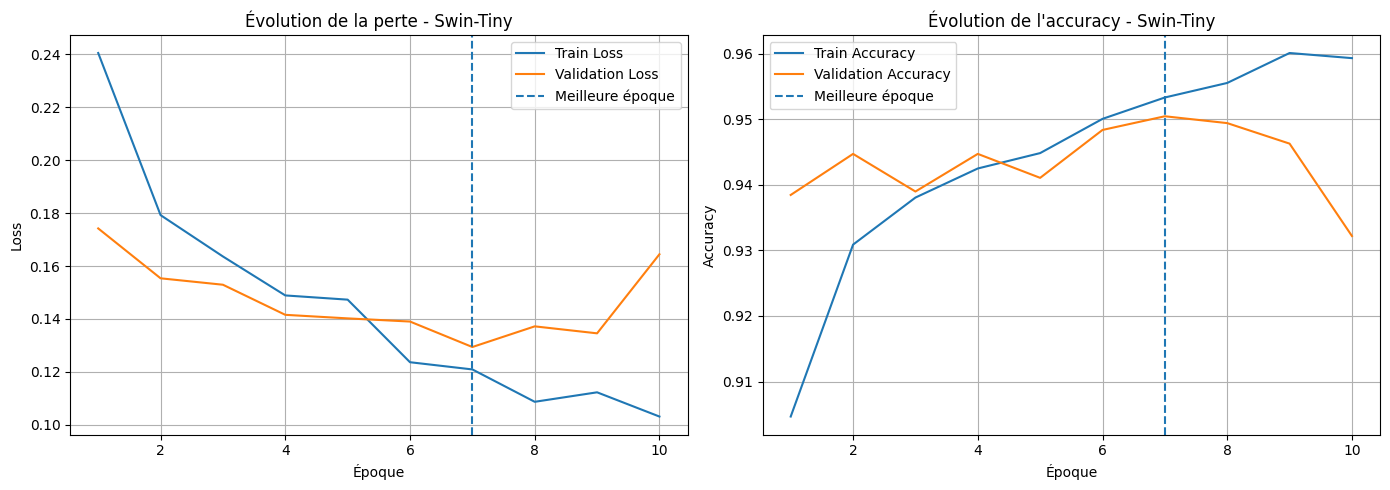

In [18]:
import matplotlib.pyplot as plt

# Je récupère les valeurs enregistrées pendant les 10 époques.
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

# Évolution de la fonction de perte.
plt.subplot(1, 2, 1)
plt.plot(epochs, history_swin["train_loss"], label="Train Loss")
plt.plot(epochs, history_swin["valid_loss"], label="Validation Loss")
plt.axvline(7, linestyle="--", label="Meilleure époque")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la perte - Swin-Tiny")
plt.legend()
plt.grid()

# Évolution de la précision.
plt.subplot(1, 2, 2)
plt.plot(epochs, history_swin["train_accuracy"], label="Train Accuracy")
plt.plot(epochs, history_swin["valid_accuracy"], label="Validation Accuracy")
plt.axvline(7, linestyle="--", label="Meilleure époque")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.title("Évolution de l'accuracy - Swin-Tiny")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

pour train :

- Loss diminue progressivement de 0.2405 à 0.1031. Cela montre que le modèle apprend de mieux en mieux les données d'entraînement.

- L'Accuracy augmente de 90.47 % à 95.93 %.


pour Validation : 

- Loss diminue jusqu'à l'époque 7, où elle atteint son minimum de 0.1294 et après l'époque 7, elle augmente à l'époque 10 où elle atteint 0.1645.

- L'Accuracy atteint son maximum de 95.04 % à l'époque 7.


  --> les performances sur les données d'entraînement continuent de s'améliorer, tandis que celles sur les données de validation se dégradent à la fin. Cela confirme le début de surapprentissage.


## Evaluation et comparaison des modèles

Restauration des 2 modèles

In [23]:
# Je reconstruis ConvNeXt-Tiny et sa couche de classification.
model_convnext = models.convnext_tiny(weights=None)
model_convnext.classifier[2] = nn.Linear(
    model_convnext.classifier[2].in_features, 2
)

# Je charge les meilleurs poids de ConvNeXt.
checkpoint_convnext = torch.load(CONVNEXT_PATH, map_location=device)
model_convnext.load_state_dict(
    checkpoint_convnext["model_state_dict"]
)

# Je reconstruis Swin-Tiny et sa couche de classification.
model_swin = models.swin_t(weights=None)
model_swin.head = nn.Linear(model_swin.head.in_features, 2)

# Je charge les meilleurs poids de Swin.
checkpoint_swin = torch.load(SWIN_PATH, map_location=device)
model_swin.load_state_dict(checkpoint_swin)

# Je prépare les deux modèles pour l'évaluation.
model_convnext = model_convnext.to(device).eval()
model_swin = model_swin.to(device).eval()

print("Les deux meilleurs modèles sont restaurés.")

Les deux meilleurs modèles sont restaurés.


In [7]:
# Je reconstruis l'architecture ConvNeXt-Tiny.
model_convnext = models.convnext_tiny(weights=None)

# Je remplace la couche finale pour nos deux classes.
in_features = model_convnext.classifier[2].in_features
model_convnext.classifier[2] = nn.Linear(in_features, 2)

# Je récupère le checkpoint et ses meilleurs poids entraînés.
checkpoint = torch.load(CONVNEXT_PATH, map_location=device)
model_convnext.load_state_dict(checkpoint["model_state_dict"])

# Je prépare le modèle pour l'évaluation.
model_convnext = model_convnext.to(device)
model_convnext.eval()

print("Meilleur modèle ConvNeXt-Tiny chargé.")
print("Époque retenue :", checkpoint["epoch"])
print("Validation Loss :", checkpoint["valid_loss"])
print("Validation Accuracy :", checkpoint["valid_accuracy"])

Meilleur modèle ConvNeXt-Tiny chargé.
Époque retenue : 2
Validation Loss : 0.1336355163566632
Validation Accuracy : 0.9420970266040689


In [24]:
# Je vérifie le nombre d'images et les classes du jeu de Test.
print("Nombre d'images :", len(test_dataset))
print("Classes :", test_dataset.classes)
print("Nombre de batches :", len(test_loader))

Nombre d'images : 999
Classes : ['benign', 'malignant']
Nombre de batches : 32


In [25]:
import torch
import numpy as np

def get_predictions(model, loader):
    # Je place le modèle en mode évaluation, sans modifier ses poids.
    model.eval()

    # Je prépare des listes pour conserver les résultats de chaque image.
    all_labels = []
    all_predictions = []
    all_probabilities = []

    # Je désactive le calcul des gradients car le modèle ne sera pas entraîné.
    with torch.no_grad():
        # Je traite les images batch par batch.
        for images, labels in loader:
            images = images.to(device)

            # Je récupère les scores produits par le modèle.
            outputs = model(images)

            # Je transforme les scores en probabilités pour chaque classe.
            probabilities = torch.softmax(outputs, dim=1)

            # Je sélectionne la classe ayant la probabilité la plus élevée.
            predictions = torch.argmax(probabilities, dim=1)

            # Je conserve les vraies classes, les prédictions
            # et les probabilités associées à la classe malignant (1).
            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities[:, 1].cpu().numpy())

    # Je retourne les résultats sous forme de tableaux NumPy.
    return (
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )

# Je génère les prédictions de ConvNeXt sur le jeu de Test.
y_true, y_pred_convnext, y_prob_convnext = get_predictions(
    model_convnext, test_loader
)

# Je génère les prédictions de Swin sur le même jeu de Test.
# Les vraies étiquettes étant identiques, je ne les récupère pas une deuxième fois.
_, y_pred_swin, y_prob_swin = get_predictions(
    model_swin, test_loader
)

print("Prédictions générées avec succès.")
print("Nombre de prédictions ConvNeXt :", len(y_pred_convnext))
print("Nombre de prédictions Swin :", len(y_pred_swin))

Prédictions générées avec succès.
Nombre de prédictions ConvNeXt : 999
Nombre de prédictions Swin : 999


In [26]:
# Je vérifie que les deux modèles ont traité toutes les images de Test.
print("Nombre de vraies étiquettes :", len(y_true))
print("Prédictions ConvNeXt :", len(y_pred_convnext))
print("Prédictions Swin :", len(y_pred_swin))

# Je vérifie que les probabilités ont également été conservées.
print("Probabilités ConvNeXt :", len(y_prob_convnext))
print("Probabilités Swin :", len(y_prob_swin))

# Je vérifie que les vraies étiquettes sont identiques pour les deux évaluations.
print("Même jeu de Test :", len(y_true) == len(y_pred_convnext) == len(y_pred_swin))

Nombre de vraies étiquettes : 999
Prédictions ConvNeXt : 999
Prédictions Swin : 999
Probabilités ConvNeXt : 999
Probabilités Swin : 999
Même jeu de Test : True


**Calcul des métriques**

In [9]:

import numpy as np
import matplotlib.pyplot as plt
import csv
import json
import shutil

from pathlib import Path


In [28]:
# Je prépare un dossier pour conserver les résultats.
SAVE_DIR = Path("/kaggle/working/evaluation_test_backup")
SAVE_DIR.mkdir(exist_ok=True)

# Je sauvegarde toutes les prédictions pour éviter de refaire l'inférence.
np.savez_compressed(
    SAVE_DIR / "predictions_test.npz",
    y_true=y_true,
    y_pred_convnext=y_pred_convnext,
    y_prob_convnext=y_prob_convnext,
    y_pred_swin=y_pred_swin,
    y_prob_swin=y_prob_swin
)

# Je conserve les informations principales de l'évaluation.
metadata = {
    "test_images": len(y_true),
    "classes": ["benign", "malignant"],
    "convnext_best_epoch": 2,
    "swin_best_epoch": 7
}

with open(SAVE_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Sauvegarde des prédictions terminée.")
print("Fichiers :", list(SAVE_DIR.iterdir()))

Sauvegarde des prédictions terminée.
Fichiers : [PosixPath('/kaggle/working/evaluation_test_backup/predictions_test.npz'), PosixPath('/kaggle/working/evaluation_test_backup/metadata.json')]


In [1]:
# Je récupère les prédictions sauvegardées dans le Dataset Kaggle.
DATA_DIR = "/kaggle/input/datasets/aminaelmoubtahij/skin-cancer-test-predictions"

data = np.load(f"{DATA_DIR}/predictions_test.npz")

# Je restaure les résultats des deux modèles.
y_true = data["y_true"]
y_pred_convnext = data["y_pred_convnext"]
y_prob_convnext = data["y_prob_convnext"]
y_pred_swin = data["y_pred_swin"]
y_prob_swin = data["y_prob_swin"]

# Je restaure les informations de l'évaluation.
with open(f"{DATA_DIR}/metadata.json", "r") as f:
    metadata = json.load(f)

print("Prédictions restaurées avec succès.")
print("Nombre d'images :", len(y_true))
print("Classes :", metadata["classes"])
print("Meilleure époque ConvNeXt :", metadata["convnext_best_epoch"])
print("Meilleure époque Swin :", metadata["swin_best_epoch"])

Prédictions restaurées avec succès.
Nombre d'images : 999
Classes : ['benign', 'malignant']
Meilleure époque ConvNeXt : 2
Meilleure époque Swin : 7


In [2]:
# Je vérifie que toutes les données nécessaires sont disponibles.
print("Vraies étiquettes :", len(y_true))
print("Prédictions ConvNeXt :", len(y_pred_convnext))
print("Probabilités ConvNeXt :", len(y_prob_convnext))
print("Prédictions Swin :", len(y_pred_swin))
print("Probabilités Swin :", len(y_prob_swin))

# Je vérifie que les données ont les mêmes dimensions.
print(
    "Toutes les dimensions sont correctes :",
    len(y_true) == len(y_pred_convnext)
    == len(y_prob_convnext)
    == len(y_pred_swin)
    == len(y_prob_swin)
)

Vraies étiquettes : 999
Prédictions ConvNeXt : 999
Probabilités ConvNeXt : 999
Prédictions Swin : 999
Probabilités Swin : 999
Toutes les dimensions sont correctes : True


**Évaluation des modèles**

In [15]:

import json
import csv
from pathlib import Path

# Je crée un dossier pour conserver les historiques.
HISTORY_DIR = Path("/kaggle/working/training_histories")
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

# Je regroupe les historiques des deux modèles.
histories = {
    "ConvNeXt-Tiny": history_convnext,
    "Swin-Tiny": history_swin
}

# Je sauvegarde les historiques au format JSON.
with open(HISTORY_DIR / "training_histories.json", "w") as file:
    json.dump(histories, file, indent=4)

# Je sauvegarde également les résultats dans un fichier CSV.
with open(HISTORY_DIR / "training_histories.csv", "w", newline="") as file:
    writer = csv.writer(file)

    writer.writerow([
        "Model", "Epoch",
        "Train_Loss", "Train_Accuracy",
        "Valid_Loss", "Valid_Accuracy"
    ])

    for model_name, history in histories.items():
        for epoch in range(10):
            writer.writerow([
                model_name,
                epoch + 1,
                history["train_loss"][epoch],
                history["train_accuracy"][epoch],
                history["valid_loss"][epoch],
                history["valid_accuracy"][epoch]
            ])

# Je regroupe les deux fichiers dans une archive ZIP.
import shutil

shutil.make_archive(
    "/kaggle/working/training_histories",
    "zip",
    HISTORY_DIR
)

print("Historiques enregistrés avec succès.")
print("Dossier :", HISTORY_DIR)
print("Fichiers :", list(HISTORY_DIR.iterdir()))


Historiques enregistrés avec succès.
Dossier : /kaggle/working/training_histories
Fichiers : [PosixPath('/kaggle/working/training_histories/training_histories.csv'), PosixPath('/kaggle/working/training_histories/training_histories.json')]


In [39]:
import numpy as np
import matplotlib.pyplot as plt

import csv
import shutil
from pathlib import Path

# Je regroupe les prédictions et les historiques des deux modèles.
predictions = {
    "ConvNeXt-Tiny": {
        "y_pred": y_pred_convnext,
        "y_prob": y_prob_convnext,
        "history": history_convnext
    },
    "Swin-Tiny": {
        "y_pred": y_pred_swin,
        "y_prob": y_prob_swin,
        "history": history_swin
    }
}

**Matrices de confusion et métriques**

In [40]:
def calculate_confusion_values(y_true, y_pred):

    # Je calcule les quatre catégories de prédictions.
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    return {
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP
    }


def calculate_roc_auc(y_true, y_prob):

    # Je compare les probabilités des images malignes
    # avec celles des images bénignes.
    positive_scores = y_prob[y_true == 1]
    negative_scores = y_prob[y_true == 0]

    comparisons = positive_scores[:, None] - negative_scores[None, :]

    return (
        np.sum(comparisons > 0)
        + 0.5 * np.sum(comparisons == 0)
    ) / comparisons.size


def calculate_metrics(confusion, y_true, y_prob):

    TP = confusion["TP"]
    TN = confusion["TN"]
    FP = confusion["FP"]
    FN = confusion["FN"]

    # Je calcule les métriques de classification.
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

    f1_score = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    roc_auc = calculate_roc_auc(y_true, y_prob)

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1-score": f1_score,
        "ROC-AUC": roc_auc
    }


# Je calcule les matrices de confusion et les métriques.
confusion_convnext = calculate_confusion_values(
    y_true, y_pred_convnext
)

confusion_swin = calculate_confusion_values(
    y_true, y_pred_swin
)

metrics_convnext = calculate_metrics(
    confusion_convnext, y_true, y_prob_convnext
)

metrics_swin = calculate_metrics(
    confusion_swin, y_true, y_prob_swin
)

# Je rassemble les résultats pour faciliter leur utilisation.
confusions = {
    "ConvNeXt-Tiny": confusion_convnext,
    "Swin-Tiny": confusion_swin
}

metrics = {
    "ConvNeXt-Tiny": metrics_convnext,
    "Swin-Tiny": metrics_swin
}


# Je présente la comparaison des performances.
print("=" * 75)
print("       COMPARAISON DES PERFORMANCES SUR LE JEU DE TEST")
print("=" * 75)

print(f"{'Métrique':<18} {'ConvNeXt-Tiny':>22} {'Swin-Tiny':>22}")
print("-" * 75)

for metric in metrics_convnext:
    value_convnext = metrics_convnext[metric] * 100
    value_swin = metrics_swin[metric] * 100

    print(
        f"{metric:<18}"
        f"{value_convnext:>21.2f}%"
        f"{value_swin:>22.2f}%"
    )

print("=" * 75)

       COMPARAISON DES PERFORMANCES SUR LE JEU DE TEST
Métrique                    ConvNeXt-Tiny              Swin-Tiny
---------------------------------------------------------------------------
Accuracy                          91.39%                 92.39%
Precision                         95.20%                 95.49%
Recall                            87.20%                 89.00%
Specificity                       95.59%                 95.79%
F1-score                          91.02%                 92.13%
ROC-AUC                           98.04%                 98.02%


**Analyse d'erreur**

In [46]:
def analyze_errors(y_true, y_pred):

    # Je récupère les indices des images mal classées.
    false_positives = np.where(
        (y_true == 0) & (y_pred == 1)
    )[0]

    false_negatives = np.where(
        (y_true == 1) & (y_pred == 0)
    )[0]

    return false_positives, false_negatives


# Je réalise l'analyse des erreurs des deux modèles.
fp_convnext, fn_convnext = analyze_errors(
    y_true, y_pred_convnext
)

fp_swin, fn_swin = analyze_errors(
    y_true, y_pred_swin
)


# Je présente une comparaison des erreurs.
print("=" * 60)
print("                 ANALYSE DES ERREURS")
print("=" * 60)

print(f"{'Type d erreur':<25} {'ConvNeXt-Tiny':>15} {'Swin-Tiny':>15}")
print("-" * 60)

print(f"{'False Positives':<25} {len(fp_convnext):>15} {len(fp_swin):>15}")
print(f"{'False Negatives':<25} {len(fn_convnext):>15} {len(fn_swin):>15}")

print("-" * 60)
print(f"{'Total des erreurs':<25} "
      f"{len(fp_convnext) + len(fn_convnext):>15} "
      f"{len(fp_swin) + len(fn_swin):>15}")

print("=" * 60)

                 ANALYSE DES ERREURS
Type d erreur               ConvNeXt-Tiny       Swin-Tiny
------------------------------------------------------------
False Positives                        22              21
False Negatives                        64              55
------------------------------------------------------------
Total des erreurs                      86              76


**Évolution de l'apprentissage**

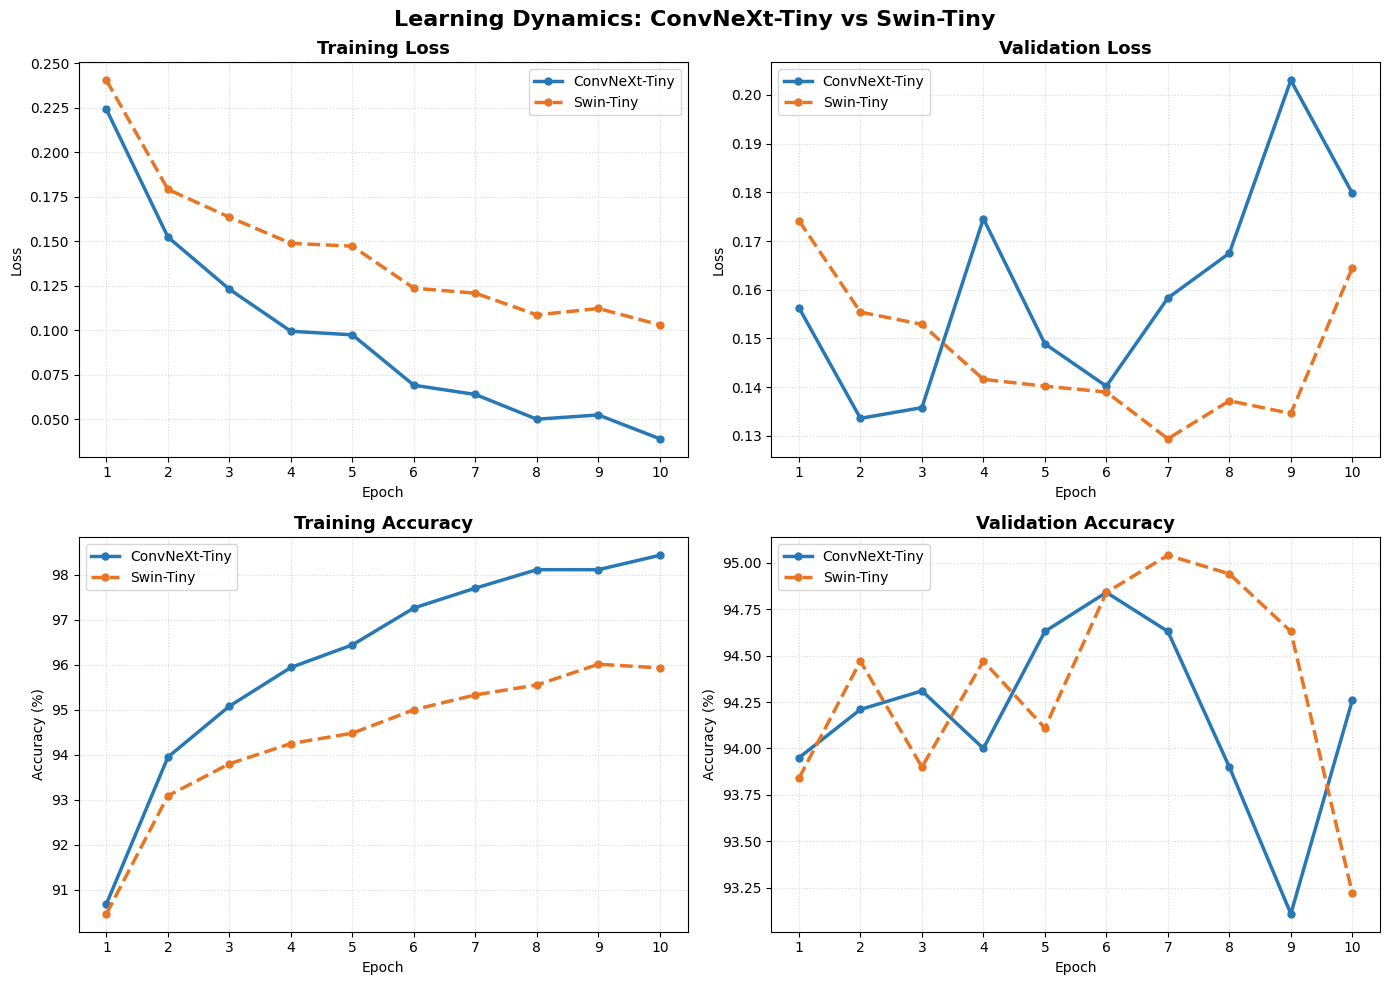

In [49]:
# Je définis les époques et les styles des deux modèles.
epochs = np.arange(1, 11)

models = {
    "ConvNeXt-Tiny": {
        "history": history_convnext,
        "color": "#2878B5",
        "style": "-"
    },
    "Swin-Tiny": {
        "history": history_swin,
        "color": "#E87524",
        "style": "--"
    }
}

# Je crée une figure comparative avec quatre graphiques.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig_learning_dynamics = fig

plots = [
    ("train_loss", "Training Loss", "Loss"),
    ("valid_loss", "Validation Loss", "Loss"),
    ("train_accuracy", "Training Accuracy", "Accuracy (%)"),
    ("valid_accuracy", "Validation Accuracy", "Accuracy (%)")
]

for ax, (metric, title, ylabel) in zip(axes.flat, plots):

    for model_name, model_data in models.items():

        values = model_data["history"][metric]

        if "accuracy" in metric:
            values = np.array(values) * 100

        ax.plot(
            epochs,
            values,
            color=model_data["color"],
            linestyle=model_data["style"],
            linewidth=2.5,
            marker="o",
            markersize=5,
            label=model_name
        )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_xticks(epochs)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend()

fig.suptitle(
    "Learning Dynamics: ConvNeXt-Tiny vs Swin-Tiny",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Comparison des matrices de confusion**

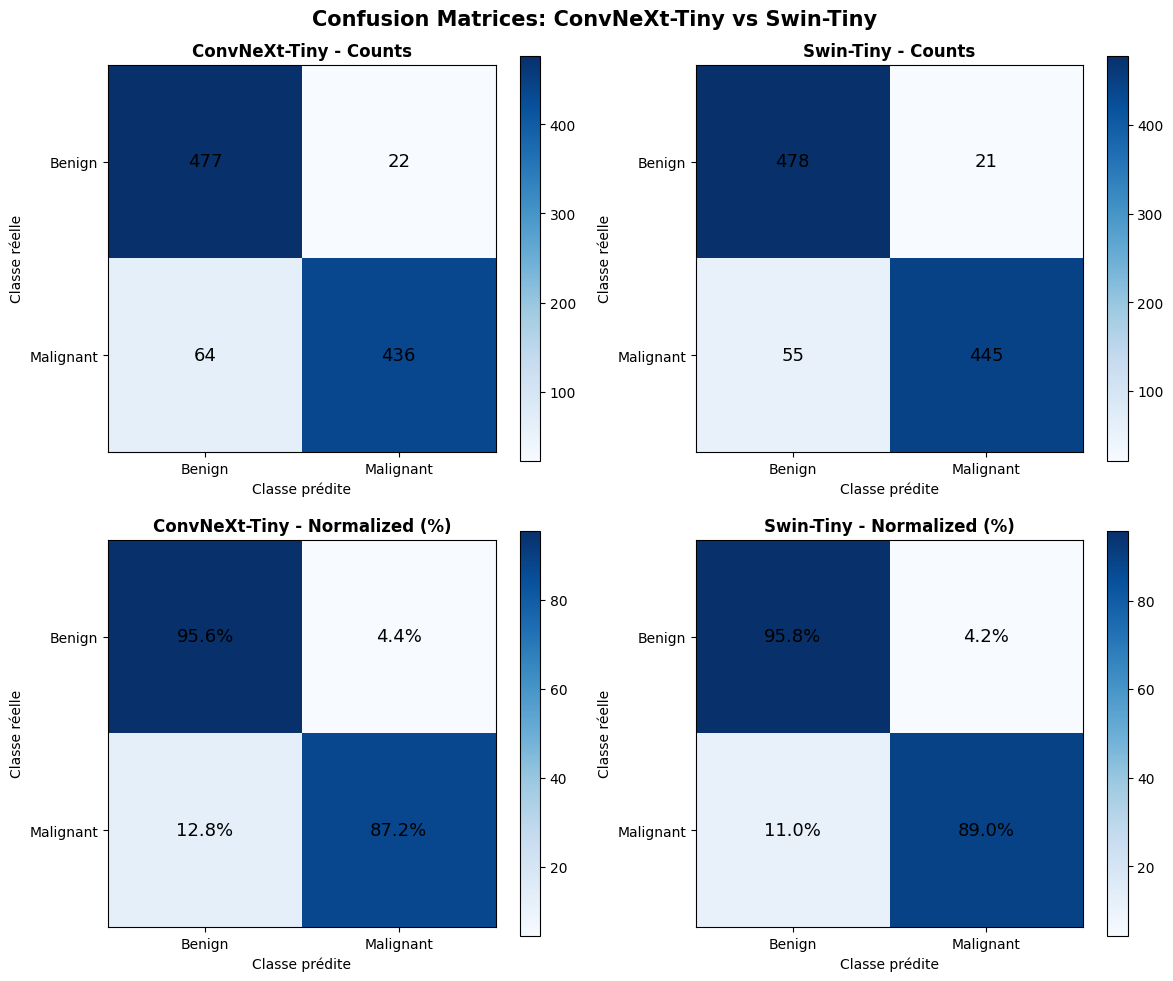

In [50]:
# Je crée une figure pour comparer les matrices des deux modèles.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig_confusion_matrices = fig
for column, (model_name, confusion) in enumerate(confusions.items()):

    cm = np.array([
        [confusion["TN"], confusion["FP"]],
        [confusion["FN"], confusion["TP"]]
    ])

    # Je normalise chaque ligne pour obtenir les pourcentages.
    cm_normalized = cm / cm.sum(axis=1, keepdims=True) * 100

    for row, (matrix, title) in enumerate([
        (cm, f"{model_name} - Counts"),
        (cm_normalized, f"{model_name} - Normalized (%)")
    ]):

        ax = axes[row, column]
        image = ax.imshow(matrix, cmap="Blues")

        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Classe prédite")
        ax.set_ylabel("Classe réelle")

        ax.set_xticks([0, 1], labels=["Benign", "Malignant"])
        ax.set_yticks([0, 1], labels=["Benign", "Malignant"])

        for i in range(2):
            for j in range(2):

                value = (
                    f"{matrix[i, j]:.1f}%"
                    if row == 1
                    else f"{int(matrix[i, j])}"
                )

                ax.text(
                    j, i, value,
                    ha="center",
                    va="center",
                    fontsize=13,
                    color="black"
                )

        fig.colorbar(image, ax=ax)

plt.suptitle(
    "Confusion Matrices: ConvNeXt-Tiny vs Swin-Tiny",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**courbe ROC et precision-recall**

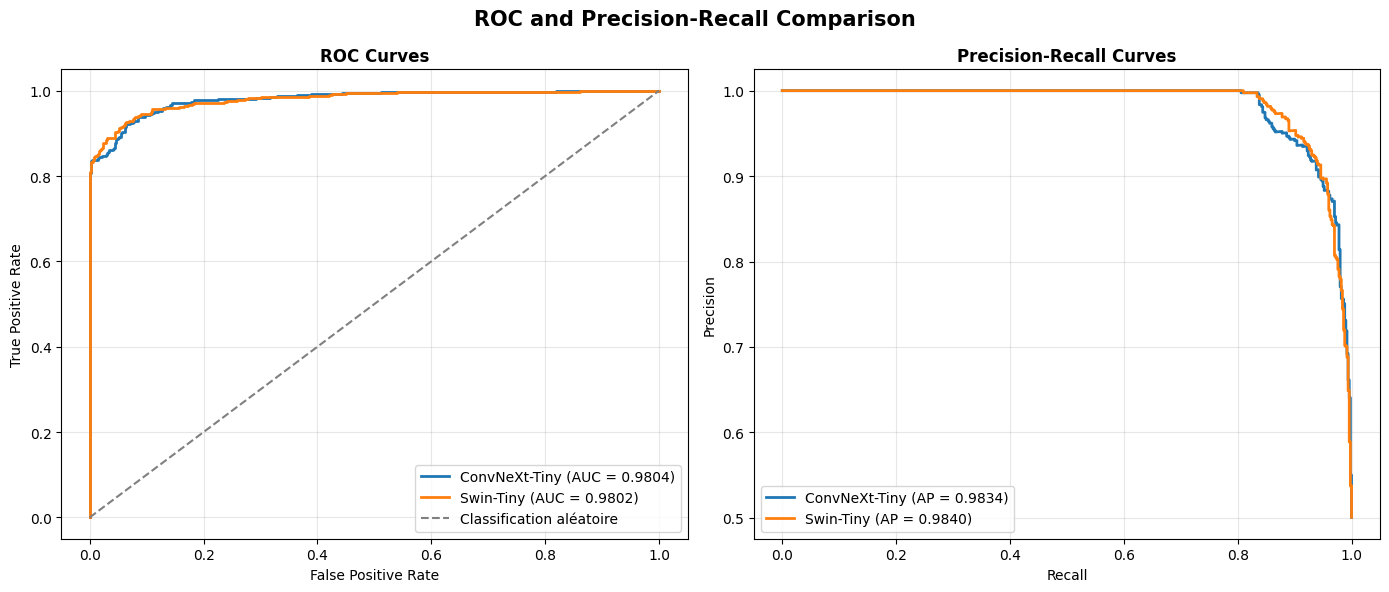

In [65]:
def calculate_roc_curve(y_true, y_prob):

    thresholds = np.sort(np.unique(y_prob))[::-1]
    thresholds = np.append(np.append(np.inf, thresholds), -np.inf)

    tpr_values = []
    fpr_values = []

    for threshold in thresholds:

        predictions = (y_prob >= threshold).astype(int)

        TP = np.sum((y_true == 1) & (predictions == 1))
        TN = np.sum((y_true == 0) & (predictions == 0))
        FP = np.sum((y_true == 0) & (predictions == 1))
        FN = np.sum((y_true == 1) & (predictions == 0))

        tpr_values.append(TP / (TP + FN))
        fpr_values.append(FP / (FP + TN))

    return np.array(fpr_values), np.array(tpr_values)


def calculate_pr_curve(y_true, y_prob):

    thresholds = np.sort(np.unique(y_prob))[::-1]
    thresholds = np.append(np.append(np.inf, thresholds), -np.inf)

    precision_values = []
    recall_values = []

    for threshold in thresholds:

        predictions = (y_prob >= threshold).astype(int)

        TP = np.sum((y_true == 1) & (predictions == 1))
        FP = np.sum((y_true == 0) & (predictions == 1))
        FN = np.sum((y_true == 1) & (predictions == 0))

        precision = TP / (TP + FP) if (TP + FP) > 0 else 1
        recall = TP / (TP + FN)

        precision_values.append(precision)
        recall_values.append(recall)

    return np.array(recall_values), np.array(precision_values)


# Je calcule les courbes et les valeurs d'Average Precision.
curves = {}

for model_name, model_data in predictions.items():

    fpr, tpr = calculate_roc_curve(y_true, model_data["y_prob"])
    recall, precision = calculate_pr_curve(y_true, model_data["y_prob"])

    average_precision = np.sum(
        np.diff(recall) * precision[1:]
    )

    curves[model_name] = {
        "fpr": fpr,
        "tpr": tpr,
        "recall": recall,
        "precision": precision,
        "average_precision": average_precision
    }


# Je représente les courbes ROC et Precision-Recall.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig_roc_pr = fig

for model_name in predictions:

    curve = curves[model_name]

    axes[0].plot(
        curve["fpr"],
        curve["tpr"],
        linewidth=2,
        label=f"{model_name} (AUC = {metrics[model_name]['ROC-AUC']:.4f})"
    )

    axes[1].plot(
        curve["recall"],
        curve["precision"],
        linewidth=2,
        label=f"{model_name} (AP = {curve['average_precision']:.4f})"
    )

# Je représente les références des deux graphiques.
axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Classification aléatoire"
)

axes[0].set_title("ROC Curves", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Precision-Recall Curves", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "ROC and Precision-Recall Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**calibration des probabilités**

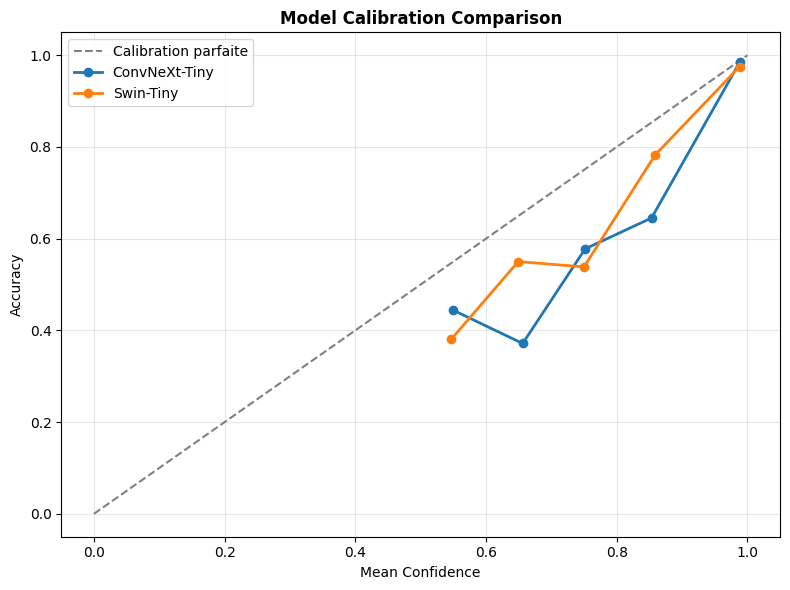

In [71]:
def calculate_calibration(y_true, y_pred, y_prob, n_bins=10):

    # Je récupère la confiance associée à la classe prédite.
    confidence = np.where(
        y_pred == 1,
        y_prob,
        1 - y_prob
    )

    correct = (y_pred == y_true).astype(int)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    mean_confidence = []
    accuracy_per_bin = []

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i])
                & (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i])
                & (confidence < bin_edges[i + 1])
            )

        if np.any(mask):

            mean_confidence.append(np.mean(confidence[mask]))
            accuracy_per_bin.append(np.mean(correct[mask]))

    return np.array(mean_confidence), np.array(accuracy_per_bin)


# Je calcule les valeurs de calibration des deux modèles.
calibration = {}

for model_name, model_data in predictions.items():

    mean_confidence, accuracy_per_bin = calculate_calibration(
        y_true,
        model_data["y_pred"],
        model_data["y_prob"]
    )

    calibration[model_name] = {
        "confidence": mean_confidence,
        "accuracy": accuracy_per_bin
    }


# Je compare la confiance prédite avec la précision réelle.
fig, ax = plt.subplots(figsize=(8, 6))
fig_calibration = fig

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Calibration parfaite"
)

for model_name, values in calibration.items():

    ax.plot(
        values["confidence"],
        values["accuracy"],
        marker="o",
        linewidth=2,
        label=model_name
    )

ax.set_title("Model Calibration Comparison", fontweight="bold")
ax.set_xlabel("Mean Confidence")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Analyse des erreurs**

In [55]:
# Je vérifie quelles images sont correctement classées par chaque modèle.
correct_convnext = y_pred_convnext == y_true
correct_swin = y_pred_swin == y_true

error_groups = {
    "Correct by both": correct_convnext & correct_swin,
    "Wrong by both": ~correct_convnext & ~correct_swin,
    "ConvNeXt only": correct_convnext & ~correct_swin,
    "Swin only": ~correct_convnext & correct_swin
}

# Je récupère les indices et les nombres d'images de chaque groupe.
error_indices = {
    name: np.where(mask)[0]
    for name, mask in error_groups.items()
}

error_counts = {
    name: len(indices)
    for name, indices in error_indices.items()
}

# Je vérifie que toutes les images sont prises en compte.
assert sum(error_counts.values()) == len(y_true)

print("COMPARAISON DES ERREURS")
print("-" * 50)

for name, count in error_counts.items():
    print(f"{name:<25} : {count}")

COMPARAISON DES ERREURS
--------------------------------------------------
Correct by both           : 900
Wrong by both             : 63
ConvNeXt only             : 13
Swin only                 : 23


In [73]:
# Je prépare les dossiers de sauvegarde.
RESULTS_DIR = Path("/kaggle/working/evaluation_result")
DATA_DIR = RESULTS_DIR / "data"
FIGURES_DIR = RESULTS_DIR / "figures"

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 1. Sauvegarde des métriques
# --------------------------------------------------

with open(DATA_DIR / "model_metrics.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Metric",
        "ConvNeXt-Tiny",
        "Swin-Tiny"
    ])

    for metric in metrics_convnext:

        writer.writerow([
            metric,
            metrics_convnext[metric],
            metrics_swin[metric]
        ])


# --------------------------------------------------
# 2. Sauvegarde des matrices de confusion
# --------------------------------------------------

with open(DATA_DIR / "confusion_values.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow(["Model", "TN", "FP", "FN", "TP"])

    for model_name, confusion in confusions.items():

        writer.writerow([
            model_name,
            confusion["TN"],
            confusion["FP"],
            confusion["FN"],
            confusion["TP"]
        ])


# --------------------------------------------------
# 3. Sauvegarde des prédictions sur le jeu de test
# --------------------------------------------------

with open(DATA_DIR / "test_predictions.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Image_Index",
        "True_Label",
        "ConvNeXt_Prediction",
        "ConvNeXt_Probability",
        "Swin_Prediction",
        "Swin_Probability"
    ])

    for i in range(len(y_true)):

        writer.writerow([
            i,
            int(y_true[i]),
            int(y_pred_convnext[i]),
            float(y_prob_convnext[i]),
            int(y_pred_swin[i]),
            float(y_prob_swin[i])
        ])


# --------------------------------------------------
# 4. Sauvegarde de l'analyse des erreurs
# --------------------------------------------------

with open(DATA_DIR / "error_analysis.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Model",
        "Error_Type",
        "Image_Indices",
        "Number_of_Images"
    ])

    error_data = {
        "ConvNeXt-Tiny": {
            "False Positives": fp_convnext,
            "False Negatives": fn_convnext
        },
        "Swin-Tiny": {
            "False Positives": fp_swin,
            "False Negatives": fn_swin
        }
    }

    for model_name, errors in error_data.items():

        for error_type, indices in errors.items():

            writer.writerow([
                model_name,
                error_type,
                ";".join(map(str, indices)),
                len(indices)
            ])


# --------------------------------------------------
# 5. Sauvegarde des courbes ROC et Precision-Recall
# --------------------------------------------------

with open(DATA_DIR / "roc_pr_curves.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Model",
        "ROC_FPR",
        "ROC_TPR",
        "PR_Recall",
        "PR_Precision"
    ])

    for model_name, curve in curves.items():

        for i in range(len(curve["fpr"])):

            writer.writerow([
                model_name,
                curve["fpr"][i],
                curve["tpr"][i],
                curve["recall"][i],
                curve["precision"][i]
            ])


# --------------------------------------------------
# 6. Sauvegarde des données de calibration
# --------------------------------------------------

with open(DATA_DIR / "calibration_values.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Model",
        "Mean_Confidence",
        "Accuracy"
    ])

    for model_name, values in calibration.items():

        for confidence, accuracy in zip(
            values["confidence"],
            values["accuracy"]
        ):

            writer.writerow([
                model_name,
                confidence,
                accuracy
            ])


# --------------------------------------------------
# 7. Sauvegarde des quatre figures
# --------------------------------------------------

figures = {
    "learning_dynamics": fig_learning_dynamics,
    "confusion_matrices": fig_confusion_matrices,
    "roc_precision_recall": fig_roc_pr,
    "calibration": fig_calibration
}

In [74]:
import shutil

# Je compresse le dossier contenant les résultats.
shutil.make_archive(
    "/kaggle/working/evaluation_result",
    "zip",
    "/kaggle/working",
    "evaluation_results"
)

'/kaggle/working/evaluation_result.zip'

In [75]:
from pathlib import Path

RESULTS_DIR = Path("/kaggle/working/evaluation_result")

for path in RESULTS_DIR.rglob("*"):
    print(path)

/kaggle/working/evaluation_result/figures
/kaggle/working/evaluation_result/data
/kaggle/working/evaluation_result/data/roc_pr_curves.csv
/kaggle/working/evaluation_result/data/test_predictions.csv
/kaggle/working/evaluation_result/data/error_analysis.csv
/kaggle/working/evaluation_result/data/calibration_values.csv
/kaggle/working/evaluation_result/data/model_metrics.csv
/kaggle/working/evaluation_result/data/confusion_values.csv


In [76]:
# Je sauvegarde les quatre figures dans le dossier figures.
figures = {
    "learning_dynamics": fig_learning_dynamics,
    "confusion_matrices": fig_confusion_matrices,
    "roc_precision_recall": fig_roc_pr,
    "calibration": fig_calibration
}

for name, fig in figures.items():
    fig.savefig(
        FIGURES_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Figures enregistrées :")
for path in FIGURES_DIR.iterdir():
    print(path.name)

Figures enregistrées :
roc_precision_recall.png
calibration.png
confusion_matrices.png
learning_dynamics.png


In [77]:
shutil.make_archive(
    "/kaggle/working/evaluation_result",
    "zip",
    "/kaggle/working",
    "evaluation_results"
)

'/kaggle/working/evaluation_result.zip'

In [72]:
print("Figure ROC-PR :", fig_roc_pr.axes[0].get_title())
print("Figure Calibration :", fig_calibration.axes[0].get_title())

Figure ROC-PR : ROC Curves
Figure Calibration : Model Calibration Comparison


In [80]:
# Je sauvegarde directement chaque figure depuis sa variable correcte.

fig_roc_pr.savefig(
    "/kaggle/working/evaluation_result/figures/roc_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

fig_calibration.savefig(
    "/kaggle/working/evaluation_result/figures/calibration.png",
    dpi=300,
    bbox_inches="tight"
)

print("ROC :", fig_roc_pr.axes[0].get_title())
print("Calibration :", fig_calibration.axes[0].get_title())

ROC : ROC Curves
Calibration : Model Calibration Comparison


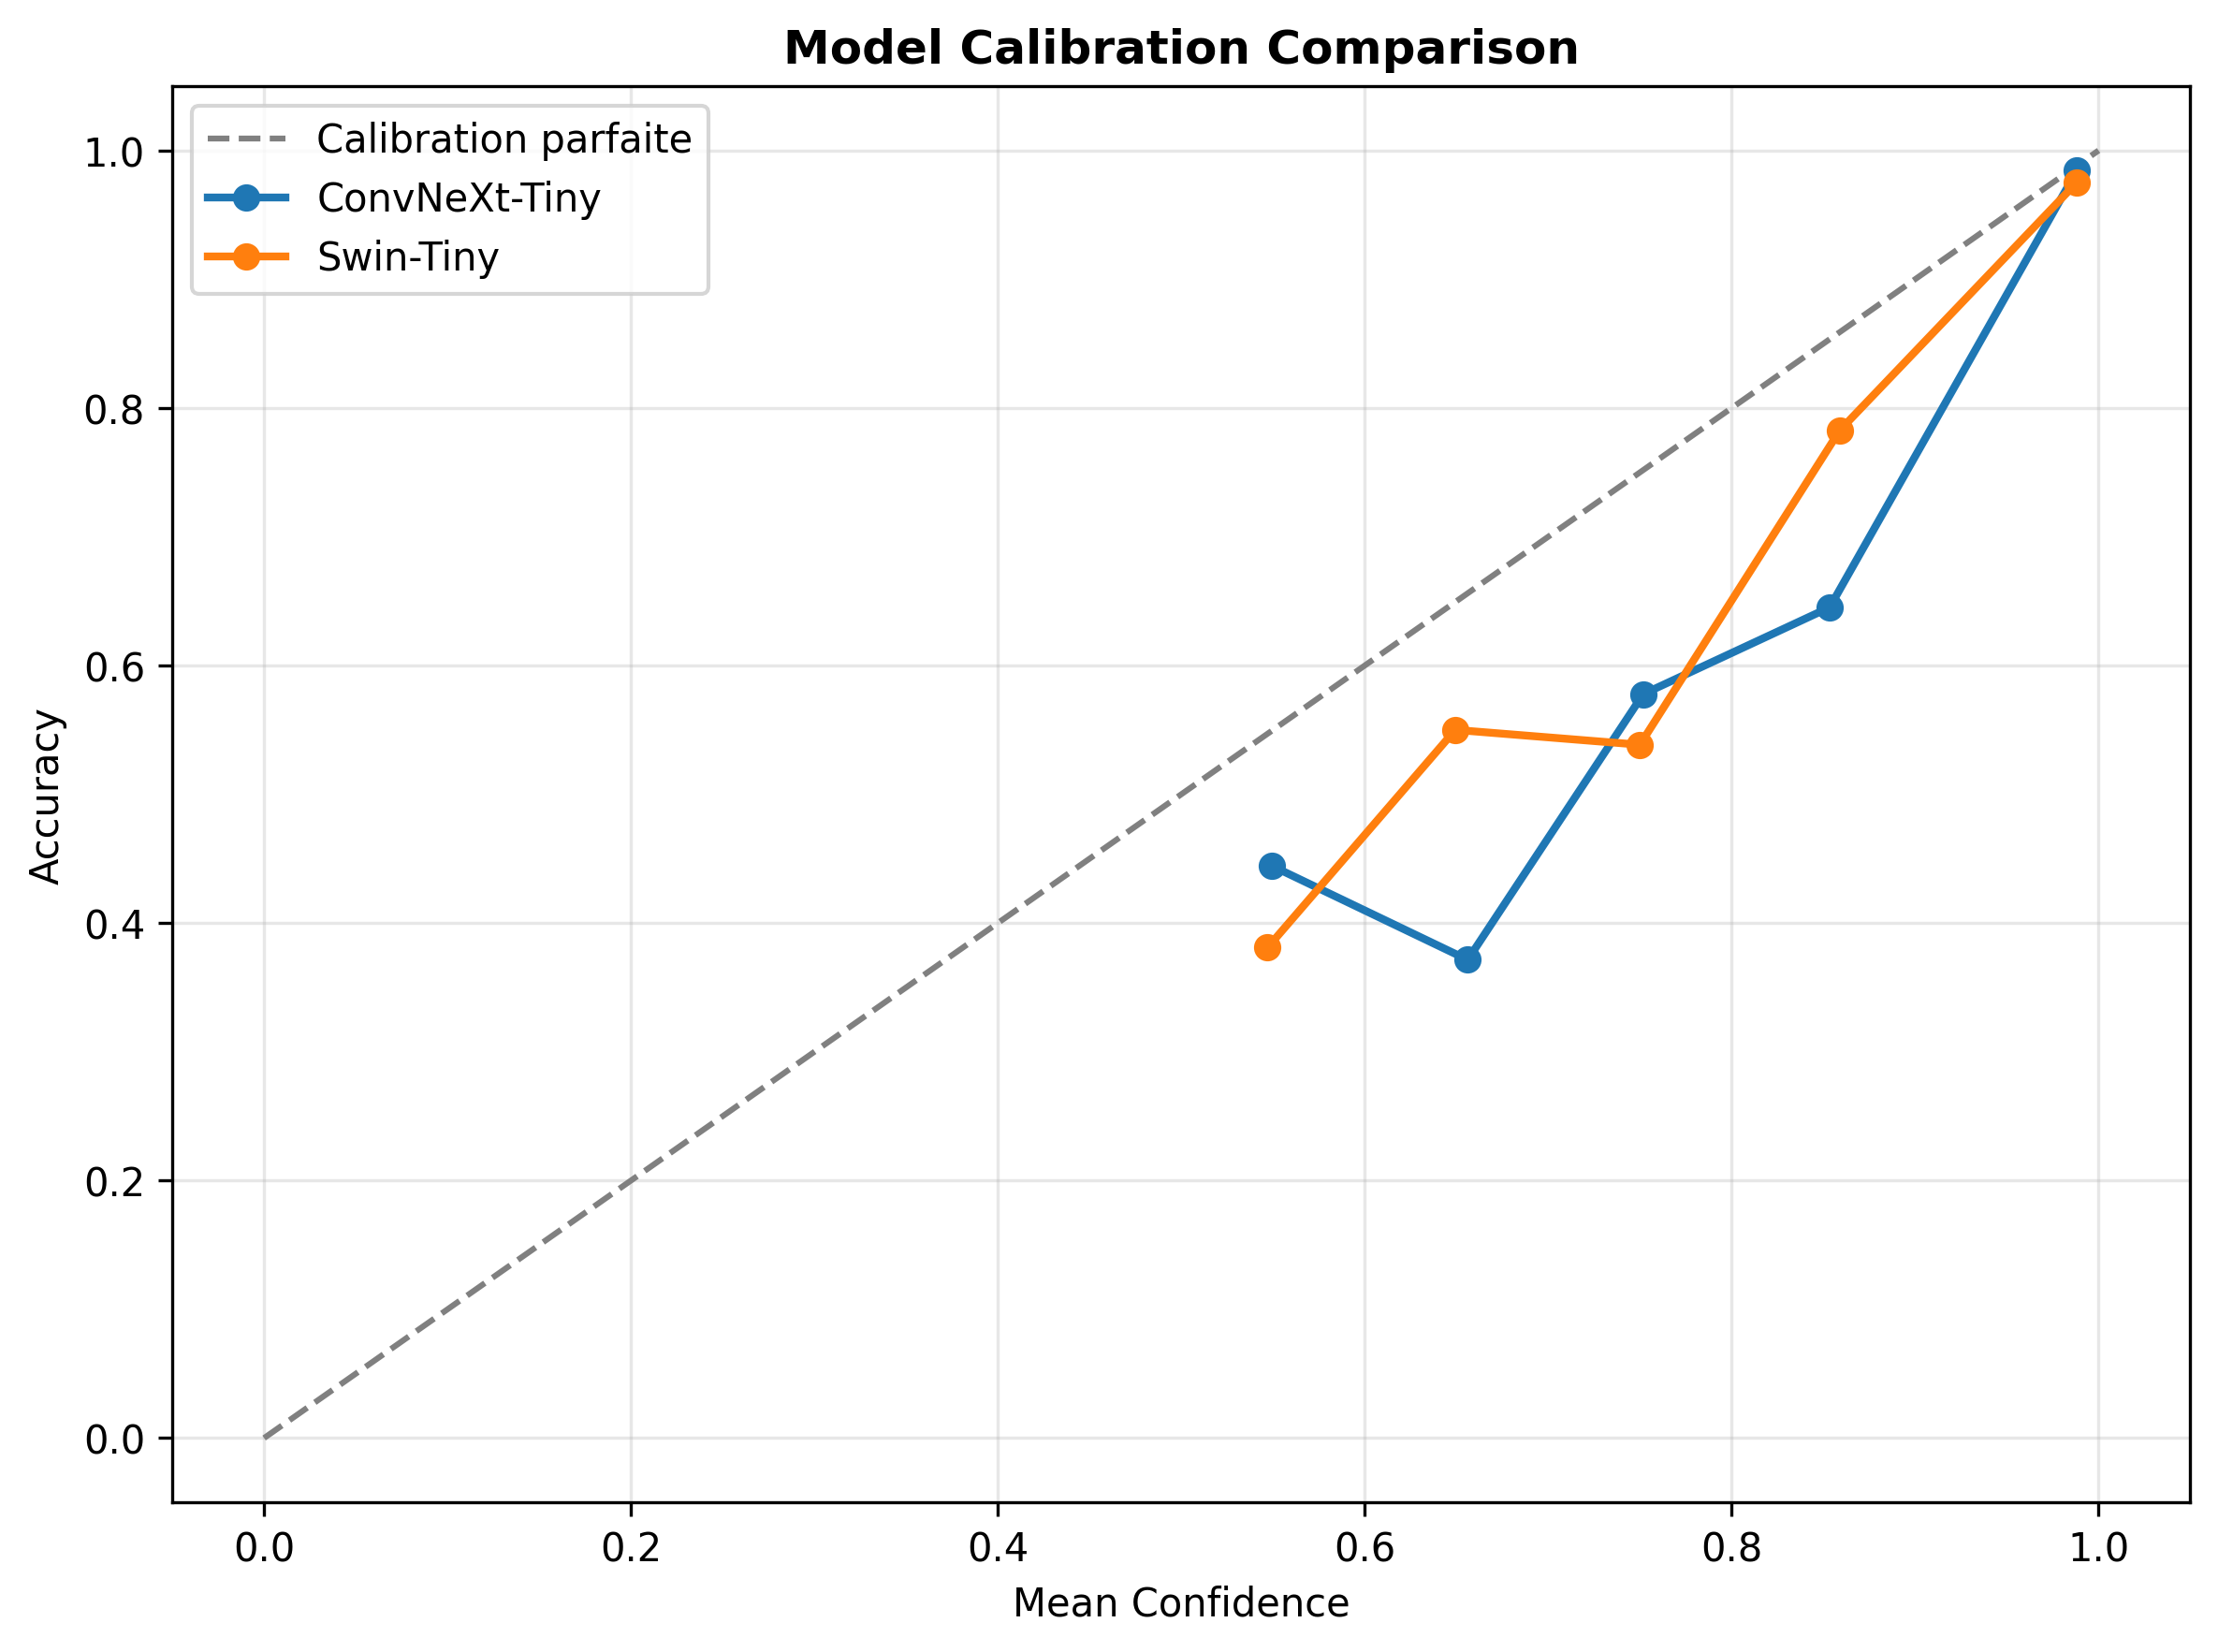

In [81]:
from PIL import Image
from IPython.display import display

display(Image.open(
    "/kaggle/working/evaluation_results/figures/calibration.png"
))

In [82]:
shutil.make_archive(
    "/kaggle/working/evaluation_result",
    "zip",
    "/kaggle/working",
    "evaluation_results"
)

'/kaggle/working/evaluation_result.zip'